# 02 - Transformação

## Pipeline de Transformação e Engenharia de Atributos

### Visão Geral e Arquitetura do Pipeline

Este notebook implementa a camada de transformação (Silver) e a construção das Tabelas Analíticas de Modelagem (ABT - Gold). O objetivo é processar os dados brutos de crédito, consolidar a variável resposta e estruturar os dados para os experimentos de modelagem no notebook `03_modeling`.

As transformações intermediárias ocorrem em memória. Apenas as bases consolidadas para modelagem são persistidas em disco. As bases brutas nunca são alteradas: todo tratamento parte de cópias.

---

### Status das Fases

| Fase | Descrição | Status |
|---|---|---|
| 1 | Higienização e tipagem (Silver) | Concluída |
| 2 | Rollup de parcelas e target | Concluída |
| 3 | Merge e ABT de baseline | Próximo passo |
| 4 | Engenharia de atributos | Pendente |
| 5 | ABT final de modelagem | Pendente |
| 6 | Base de inferência (submissão) | Pendente |

---

### Fases do Pipeline

#### 1. Higienização e Tipagem Estrutural (Camada Silver)
- `submissao_tratada`: higienização, datas inválidas sinalizadas por flag e descarte de colunas (`hora_solicitacao`, `dia_semana_solicitacao`).
- `cadastral_tratada`: relação 1:1 por cliente, consolidação de duplicatas por recência (a última ocorrência prevalece, herdando valores nulos da anterior) e flag de data de nascimento inválida. `sexo` é removida da base de modelagem por equidade.
- `emprestimos_tratada`: relação 1:1 por contrato, com conservação volumétrica integral. Colunas de crédito renomeadas (`valor_credito_concedido` e `valor_credito`) e indicador `sim/nao` convertido para 1/0.
- `parcelas_tratada`: relação 1:M por prestação, com remoção estrita de duplicatas integrais.

#### 2. Rollup de Parcelas e Construção do Target
- Agrupamento em memória gerando `parcelas_por_contrato` (grão de contrato).
- Filtro pela versão mais recente da parcela e consolidação de pagamentos fracionados (tolerância de R$ 0,01).
- Janela de observação MOB 12: `data_decisao` + 360 dias.
- Maturação: contrato maduro quando a janela termina até `max(data_real_pagamento)`.
- Evento 60+: atraso de pelo menos 60 dias (`>= 60`) cuja data de cruzamento (`data_prevista_pagamento` + 60 dias) esteja dentro da janela.
- `OVER60MOB12`: 1 = evento em contrato maduro; 0 = maduro, sem evento e sem incerteza; `<NA>` = demais casos.

#### 3. Merge e ABT de Baseline (Benchmark sem Engenharia)
- Grão `id_contrato`: `emprestimos_tratada` (left) com `cadastral_tratada` (`many_to_one`) e com a target (`one_to_one`).
- Treino = contratos com target não nula. Os demais permanecem em `base_sem_rotulo`, reservados para Reject Inference (aplicado apenas no treino).
- Sem features derivadas, encoding, escalonamento ou imputação.
- Exclusão explícita das colunas pós-decisão antes do ajuste (`status_contrato`, `motivo_recusa`, `valor_credito_concedido`, `data_liberacao`, `data_primeiro_vencimento`, `data_ultimo_vencimento_original`, `data_ultimo_vencimento`, `data_encerramento`).
- Split por cliente (ou tempo), nunca por linha.
- Persistência: `dados/abt_baseline.parquet`.

#### 4. Engenharia de Atributos
**4.1 Features por base (antes do merge)**
- Cadastral: idade e variáveis derivadas sem dependência de outras tabelas.
- Empréstimos e parcelas: histórico comportamental por cliente, calculado com corte temporal por contrato (apenas eventos anteriores a `data_decisao`).
- Nenhuma feature de desfecho do próprio contrato.

**4.2 Merge analítico completo**
- Junção das features individuais pelas chaves `id_cliente` e `id_contrato`, com `validate` e conservação de linhas.

**4.3 Features cruzadas (pós-merge)**
- Idade na decisão, comprometimento de renda, razões financeiras (crédito/bem, parcela/renda, entrada/crédito).
- Flags de ausência e de qualidade de dado, criadas apenas após fechar os tratamentos das tabelas.

#### 5. ABT Final para Modelagem
- Validações de integridade, ausência de leakage e tipagem final.
- Persistência: `dados/abt_modelagem.parquet`.

#### 6. Preparação da Base de Inferência (Submissão)
- Definição das features disponíveis na submissão: apenas as que existem na data de solicitação ou podem ser reconstruídas para ela.
- Mesmos tratamentos cadastrais da base de treino.
- Features históricas calculadas com corte em `data_solicitacao`, usando apenas empréstimos e parcelas anteriores.
- A submissão não possui `id_contrato`, portanto não se liga diretamente à target.
- Persistência da base de escoragem.

---

### Diretrizes de Engenharia e Boas Práticas

- **Prevenção de vazamento temporal:** só entram como preditores informações disponíveis na decisão (`data_decisao` no histórico, `data_solicitacao` na submissão). Features históricas por cliente respeitam o corte de cada contrato.
- **Validação por invariantes:** asserções testam consistência lógica e conservação volumétrica dinâmica, evitando valores fixos.
- **Vetorização:** sem `.apply` ou `lambda`; usar operações vetorizadas (`np.where`, `map`, `groupby`).
- **Rastreabilidade:** conversões e padronizações geram relatórios, e nenhum valor é descartado silenciosamente.
- **Equidade:** `sexo` fora da modelagem, preservável apenas para auditoria.

---

### Critério de Maturação e Target

- **Evento Mau (1):** contrato maduro com atraso de pelo menos 60 dias cruzado dentro da janela de 360 dias após `data_decisao`.
- **Evento Bom (0):** contrato maduro, sem evento e sem incerteza.
- **Indeterminado (NA):** contratos imaturos ou com incerteza (pagamento positivo sem data, valor previsto não positivo ou vencimento ausente). Ficam fora do treino supervisionado e não são rotulados como bons.

---

### Limitações Conhecidas

- Pagamentos positivos sem data podem divergir de atrasos nulos e ainda não foram reconciliados.
- A ordem das linhas do cadastral é usada como proxy de recência, pois não há coluna de data de registro.
- Há contratos de empréstimo sem parcelas e contrato aprovado com `valor_parcela` ausente, mantidos sem imputação.

In [75]:
import importlib
import sys
sys.path.append("..")

import src.functions as fn #Funcoes criadas no projeto
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve

In [53]:
# Carrega cópias de trabalho mantendo os arquivos originais intactos.
cadastral = pd.read_parquet("../dados/base_cadastral.parquet").copy()
submissao = pd.read_parquet("../dados/base_submissao.parquet").copy()
emprestimos = pd.read_parquet("../dados/historico_emprestimos.parquet").copy()
parcelas = pd.read_parquet("../dados/historico_parcelas.parquet").copy()

print(
    f"cadastral: {cadastral.shape} | submissao: {submissao.shape} | "
    f"emprestimos: {emprestimos.shape} | parcelas: {parcelas.shape}"
)

cadastral: (50600, 16) | submissao: (50400, 8) | emprestimos: (211944, 37) | parcelas: (1664384, 8)


## Tratamento - base submissao


In [54]:
# --- TRATAMENTO E TIPAGEM: SUBMISSAO ---

# 1. Referências para validação por invariantes
n_linhas_originais_sub = len(submissao)
marcador_data_invalida = "2025-13-01"
formatos_data_sub = ["%Y-%m-%d", "%d/%m/%Y"]
colunas_numericas_sub = ["valor_credito", "valor_bem", "valor_parcela"]
colunas_descartadas_sub = ["hora_solicitacao", "dia_semana_solicitacao"]

submissao_tratada = submissao.copy()

# 2. Flag da data inválida, criada antes da conversão (a string fixa viraria nulo)
submissao_tratada["data_invalida"] = (
    submissao_tratada["data_solicitacao"].astype("string").eq(marcador_data_invalida)
)

# 3. Padronização de tipo_contrato (a função retorna DataFrame e relatório)
submissao_tratada, relatorio_padronizacao_sub = fn.padronizar_categoricas(
    submissao_tratada, ["tipo_contrato"]
)

# 4. Conversão das datas: ISO primeiro, DD/MM/AAAA depois; o marcador inválido vira nulo
submissao_tratada, relatorio_tipos_sub = fn.converter_tipos(
    submissao_tratada,
    datas={"data_solicitacao": formatos_data_sub},
)

# 5. Remoção de hora e dia da semana da solicitação (a base bruta permanece intacta)
submissao_tratada = submissao_tratada.drop(columns=colunas_descartadas_sub)

# 6. Asserções de integridade
n_nulos_data = int(submissao_tratada["data_solicitacao"].isna().sum())
n_invalidas = int(submissao_tratada["data_invalida"].sum())

assert len(submissao_tratada) == n_linhas_originais_sub, "Número de linhas alterado"
assert n_nulos_data == n_invalidas, (
    f"Datas nulas ({n_nulos_data}) diferem das inválidas sinalizadas ({n_invalidas}): há formato não previsto"
)
assert pd.api.types.is_datetime64_any_dtype(submissao_tratada["data_solicitacao"]), (
    "data_solicitacao não foi convertida para datetime64"
)
assert not set(colunas_descartadas_sub) & set(submissao_tratada.columns), (
    "Colunas descartadas ainda presentes em submissao_tratada"
)
assert set(colunas_descartadas_sub) <= set(submissao.columns), (
    "A base bruta submissao deveria manter as colunas descartadas"
)
for coluna in colunas_numericas_sub:
    assert submissao_tratada[coluna].equals(submissao[coluna]), f"{coluna} foi alterada"

# 7. Relatórios
print("--- Base Submissao Tratada ---")
print(f"Linhas: {len(submissao_tratada):,}")
print(f"Colunas descartadas: {colunas_descartadas_sub}")
print(f"Datas inválidas -> nulo: {n_invalidas} ({n_invalidas / len(submissao_tratada):.2%})")
display(relatorio_padronizacao_sub)
display(relatorio_tipos_sub)
print(submissao_tratada["tipo_contrato"].value_counts(dropna=False))
print(submissao_tratada.dtypes)

--- Base Submissao Tratada ---
Linhas: 50,400
Colunas descartadas: ['hora_solicitacao', 'dia_semana_solicitacao']
Datas inválidas -> nulo: 51 (0.10%)


,coluna,n_distintos_antes,n_distintos_depois,nulos_antes,nulos_depois
0,tipo_contrato,6,3,0,0


,coluna,dtype_antes,dtype_depois,nulos_antes,nulos_depois,falhas,exemplos_falha
0,data_solicitacao,str,datetime64[us],0,51,51,[2025-13-01]


tipo_contrato
emprestimo em dinheiro      20133
financiamento de consumo    18154
credito rotativo            12113
Name: count, dtype: int64
id_cliente                   int64
data_solicitacao    datetime64[us]
tipo_contrato                  str
valor_credito              float64
valor_bem                  float64
valor_parcela              float64
data_invalida        bool[pyarrow]
dtype: object


## Tratamento de Dados para as tabelas-base de treino

In [55]:
# --- TRATAMENTO E CONSOLIDAÇÃO: BASE CADASTRAL ---

# 1. Parâmetros e referências dinâmicas (a base de partida não é modificada)
ano_limite_nascimento = 1920
formatos_data_cad = ["%Y-%m-%d", "%d/%m/%Y"]
colunas_inteiras_cad = ["qtd_membros_familia", "qtd_filhos"]
cols_para_remover = ["sexo"]
formato_data_br_regex = r"^\d{2}/\d{2}/\d{4}$"   # estrutura DD/MM/AAAA (data pode ser impossível)

n_clientes_esperados = cadastral["id_cliente"].nunique()
cadastral_proc = cadastral.copy()

# 2. Conversão de tipos (datas com formato explícito; renda só se vier como texto)
numericas_texto_cad = {}
if not pd.api.types.is_numeric_dtype(cadastral_proc["renda_anual"]):
    numericas_texto_cad["renda_anual"] = {"decimal": ",", "milhar": "."}

cadastral_proc, rel_tipos = fn.converter_tipos(
    cadastral_proc,
    datas={"data_nascimento": formatos_data_cad},
    numericas_texto=numericas_texto_cad or None,
    inteiros=colunas_inteiras_cad,
)

# 3. Explica cada falha de conversão, comparando com a base de origem
#    Data: falha esperada = texto no formato DD/MM/AAAA que não existe no calendário
txt_nasc = cadastral["data_nascimento"].astype("string")
falha_nasc = cadastral_proc["data_nascimento"].isna() & txt_nasc.notna()
nasc_explicada = falha_nasc & txt_nasc.str.match(formato_data_br_regex).fillna(False)

#    Renda: falha esperada = placeholder de ausência (padronizado como nulo na função)
placeholders_norm = {fn._normalizar(p) for p in fn.PLACEHOLDERS_PADRAO}
txt_renda = fn._normalizar_serie(cadastral["renda_anual"])
falha_renda = cadastral_proc["renda_anual"].isna() & cadastral["renda_anual"].notna()
renda_explicada = falha_renda & txt_renda.isin(placeholders_norm)

n_nasc_inexplicadas = int((falha_nasc & ~nasc_explicada).sum())
n_renda_inexplicadas = int((falha_renda & ~renda_explicada).sum())

print(f"data_nascimento: {int(falha_nasc.sum())} falhas | {int(nasc_explicada.sum())} datas impossíveis (DD/MM/AAAA)")
print(f"renda_anual: {int(falha_renda.sum())} falhas | {int(renda_explicada.sum())} placeholders")

assert n_nasc_inexplicadas == 0, (
    f"{n_nasc_inexplicadas} datas falharam fora do padrão DD/MM/AAAA: "
    f"{txt_nasc[falha_nasc & ~nasc_explicada].unique()[:5]}"
)
assert n_renda_inexplicadas == 0, (
    f"{n_renda_inexplicadas} rendas falharam sem ser placeholder: "
    f"{cadastral['renda_anual'][falha_renda & ~renda_explicada].unique()[:5]}"
)

# 4. Data de nascimento sentinela: flag a partir da data já convertida, valor vira nulo
ano_nascimento = cadastral_proc["data_nascimento"].dt.year
cadastral_proc["data_nascimento_invalida"] = ano_nascimento.le(ano_limite_nascimento)
cadastral_proc["data_nascimento"] = cadastral_proc["data_nascimento"].mask(
    cadastral_proc["data_nascimento_invalida"]
)

# 5. Padronização de categóricas e placeholders -> nulo
cols_categoricas = list(
    cadastral_proc.select_dtypes(include=["object", "string", "category"]).columns
)
cadastral_proc, rel_cat = fn.padronizar_categoricas(cadastral_proc, colunas=cols_categoricas)

# 6. Consolidação de duplicatas por id_cliente
#    Premissa documentada: a ordem das linhas indica recência (a última ocorrência é a mais recente).
#    last() devolve o último valor NÃO nulo de cada coluna.
n_linhas_antes_dedup = len(cadastral_proc)
max_ocorrencias = int(cadastral_proc["id_cliente"].value_counts().max())

cadastral_tratada = cadastral_proc.groupby("id_cliente", sort=True, as_index=False).last()

# A flag só vale se o valor consolidado continuar nulo
cadastral_tratada["data_nascimento_invalida"] = (
    cadastral_tratada["data_nascimento_invalida"].astype("bool")
    & cadastral_tratada["data_nascimento"].isna()
)

# 7. Tipos finais e remoção de colunas fora do modelo
cadastral_tratada["id_cliente"] = cadastral_tratada["id_cliente"].astype("int64")
for col in cols_categoricas:
    cadastral_tratada[col] = cadastral_tratada[col].astype("category")

n_cols_antes_drop = cadastral_tratada.shape[1]
cadastral_tratada = cadastral_tratada.drop(columns=cols_para_remover)

# 8. Asserções de integridade
assert len(cadastral_tratada) == n_clientes_esperados, (
    f"Esperado {n_clientes_esperados} clientes, obtido {len(cadastral_tratada)}"
)
assert cadastral_tratada["id_cliente"].is_unique, "id_cliente não é único na base consolidada"
assert cadastral_tratada.shape[1] == n_cols_antes_drop - len(cols_para_remover), (
    "Inconsistência no número de colunas após exclusão"
)
assert not (
    cadastral_tratada["data_nascimento_invalida"] & cadastral_tratada["data_nascimento"].notna()
).any(), "Flag de data inválida contradiz data_nascimento preenchida"
assert pd.api.types.is_datetime64_any_dtype(cadastral_tratada["data_nascimento"]), (
    "data_nascimento não é datetime64"
)

# 9. Relatório
print("--- Base Cadastral Tratada ---")
print(f"Shape final: {cadastral_tratada.shape}")
print(f"Linhas antes da deduplicação: {n_linhas_antes_dedup} | máximo de ocorrências por cliente: {max_ocorrencias}")
print(f"Clientes com data_nascimento_invalida: {int(cadastral_tratada['data_nascimento_invalida'].sum())}")
display(rel_tipos)
display(rel_cat)

data_nascimento: 38 falhas | 38 datas impossíveis (DD/MM/AAAA)
renda_anual: 101 falhas | 101 placeholders
--- Base Cadastral Tratada ---
Shape final: (50000, 16)
Linhas antes da deduplicação: 50600 | máximo de ocorrências por cliente: 2
Clientes com data_nascimento_invalida: 36


,coluna,dtype_antes,dtype_depois,nulos_antes,nulos_depois,falhas,exemplos_falha
0,data_nascimento,str,datetime64[us],0,38,38,[31/02/1990]
1,renda_anual,str,float64,0,101,101,[não informado]
2,qtd_membros_familia,float64,Int64,0,0,0,[]
3,qtd_filhos,int64,Int64,0,0,0,[]


,coluna,n_distintos_antes,n_distintos_depois,nulos_antes,nulos_depois
0,sexo,6,2,0,51
1,tipo_renda,13,9,0,60
2,ocupacao,18,18,15706,15706
3,tipo_organizacao,58,57,0,10001
4,nivel_educacao,5,5,0,0
5,estado_civil,6,5,0,150
6,tipo_moradia,6,6,0,0
7,possui_carro,7,2,0,49
8,possui_imovel,7,2,0,54


In [56]:
cadastral_tratada.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   id_cliente                  50000 non-null  int64         
 1   data_nascimento             49928 non-null  datetime64[us]
 2   qtd_filhos                  50000 non-null  Int64         
 3   qtd_membros_familia         50000 non-null  Int64         
 4   renda_anual                 49903 non-null  float64       
 5   tipo_renda                  49940 non-null  category      
 6   ocupacao                    34489 non-null  category      
 7   tipo_organizacao            40132 non-null  category      
 8   nivel_educacao              50000 non-null  category      
 9   estado_civil                50000 non-null  category      
 10  tipo_moradia                50000 non-null  category      
 11  possui_carro                49951 non-null  category      
 12  p

In [57]:
cadastral_tratada.head()

,id_cliente,data_nascimento,qtd_filhos,qtd_membros_familia,renda_anual,tipo_renda,ocupacao,tipo_organizacao,nivel_educacao,estado_civil,tipo_moradia,possui_carro,possui_imovel,nota_regiao_cliente,nota_regiao_cliente_cidade,data_nascimento_invalida
0,100023,1994-01-30,1,2,90000.0,servidor publico,equipe administrativa,educacao infantil,ensino superior,solteiro,casa ou apartamento,nao,sim,2,2,False
1,100031,1973-11-13,0,1,112500.0,assalariado,cozinheiros,entidade empresarial tipo 3,ensino medio,viuvo,casa ou apartamento,nao,sim,3,2,False
2,100056,1975-02-19,0,2,360000.0,assalariado,operarios,transporte tipo 2,ensino medio,casado,casa ou apartamento,sim,sim,2,2,False
3,100067,1996-09-03,1,3,162000.0,assalariado,equipe de vendas,comercio tipo 2,ensino superior,uniao estavel,casa ou apartamento,sim,sim,2,2,False
4,100069,1986-04-10,1,2,360000.0,assalariado,operarios,transporte tipo 4,ensino medio,separado,casa ou apartamento,sim,sim,2,2,False


In [58]:
# --- TRATAMENTO E TIPAGEM: BASE EMPRESTIMOS ---

# 1. Schema declarado (37 colunas após a renomeação, conforme .info())
formatos_data_emp = ["%Y-%m-%d", "%d/%m/%Y"]
mapa_renomeacao_emp = {
    "valor_credito": "valor_credito_concedido",  # valor efetivamente concedido (pós-decisão)
    "valor_solicitado": "valor_credito",         # alinha com a submissão
}
cols_descartar_emp = ["dia_semana_solicitacao", "hora_solicitacao"]  # mesma decisão da submissão
cols_id_emp = ["id_contrato", "id_cliente"]
cols_datas_emp = [
    "data_decisao", "data_liberacao", "data_primeiro_vencimento",
    "data_ultimo_vencimento_original", "data_ultimo_vencimento", "data_encerramento",
]
cols_float_emp = [
    "valor_credito", "valor_credito_concedido", "valor_bem", "valor_parcela",
    "valor_entrada", "percentual_entrada", "taxa_juros_padrao", "taxa_juros_promocional",
]
cols_inteiras_nulaveis_emp = ["qtd_parcelas_planejadas", "indicador_seguro_contratado"]
cols_inteiras_emp = ["area_venda", "indicador_ultima_solicitacao_dia"]

# Indicador textual (sim/nao) convertido para 1/0 após a padronização
col_indicador_texto = "indicador_ultima_solicitacao_contrato"
valor_positivo_ind, valor_negativo_ind = "sim", "nao"

cols_cat_emp = [
    "tipo_contrato", "status_contrato", "tipo_pagamento", "finalidade_emprestimo",
    "tipo_cliente", "faixa_rendimento", "tipo_portfolio", "tipo_produto",
    "categoria_bem", "combinacao_produto", "setor_vendedor", "canal_venda",
    "motivo_recusa", "acompanhantes_cliente",
]
schema_esperado_emp = (
    cols_id_emp + cols_datas_emp + cols_float_emp + cols_inteiras_nulaveis_emp
    + cols_inteiras_emp + cols_cat_emp + [col_indicador_texto] + cols_descartar_emp
)

n_linhas_esperadas_emp = len(emprestimos)
emprestimos_proc = emprestimos.copy()  # a base de partida não é modificada

# 2. Renomeação, com checagem de que as colunas de origem existem
ausentes_renomeacao = set(mapa_renomeacao_emp) - set(emprestimos_proc.columns)
assert not ausentes_renomeacao, f"Colunas ausentes para renomear: {ausentes_renomeacao}"
emprestimos_proc = emprestimos_proc.rename(columns=mapa_renomeacao_emp)

# 3. Schema: nenhuma coluna a mais nem a menos que o declarado
assert len(schema_esperado_emp) == len(set(schema_esperado_emp)), "Coluna declarada em mais de um grupo"
assert set(emprestimos_proc.columns) == set(schema_esperado_emp), (
    f"Colunas fora do schema: {set(emprestimos_proc.columns) - set(schema_esperado_emp)} | "
    f"ausentes: {set(schema_esperado_emp) - set(emprestimos_proc.columns)}"
)

# 4. Descarte das colunas definidas (antes das conversões, para não processá-las à toa)
emprestimos_proc = emprestimos_proc.drop(columns=cols_descartar_emp)

# 5. Conversão de datas (formato explícito) e inteiros com nulos
emprestimos_proc, rel_tipos_emp = fn.converter_tipos(
    emprestimos_proc,
    datas={c: formatos_data_emp for c in cols_datas_emp},
    inteiros=["qtd_parcelas_planejadas"],
)
assert (rel_tipos_emp["falhas"] == 0).all(), (
    f"Conversão descartou valores:\n{rel_tipos_emp[rel_tipos_emp['falhas'] > 0]}"
)

# 6. Padronização das categóricas e do indicador textual (minúsculas, sem acento, placeholders -> nulo)
cols_padronizar_emp = cols_cat_emp + [col_indicador_texto]
emprestimos_proc, rel_cat_emp = fn.padronizar_categoricas(emprestimos_proc, colunas=cols_padronizar_emp)

# 7. Indicador sim/nao -> 1/0 (vetorizado; para se houver valor fora do esperado ou nulo)
ind_padronizado = emprestimos_proc[col_indicador_texto]
valores_validos_ind = {valor_positivo_ind, valor_negativo_ind}
fora_do_esperado = ind_padronizado.isna() | ~ind_padronizado.isin(valores_validos_ind)
assert not fora_do_esperado.any(), (
    f"{col_indicador_texto}: {int(fora_do_esperado.sum())} valores fora de {valores_validos_ind} "
    f"(exemplos: {ind_padronizado[fora_do_esperado].unique()[:5]})"
)
emprestimos_proc[col_indicador_texto] = np.where(
    ind_padronizado.eq(valor_positivo_ind), 1, 0
).astype("int8")

# 8. Tipos finais
emprestimos_proc[cols_id_emp] = emprestimos_proc[cols_id_emp].astype("int64")
emprestimos_proc[cols_float_emp] = emprestimos_proc[cols_float_emp].astype("float64")
emprestimos_proc[cols_inteiras_emp] = emprestimos_proc[cols_inteiras_emp].astype("int64")
emprestimos_proc["indicador_seguro_contratado"] = emprestimos_proc["indicador_seguro_contratado"].astype("Int8")
emprestimos_proc[col_indicador_texto] = emprestimos_proc[col_indicador_texto].astype("Int8")
emprestimos_proc[cols_cat_emp] = emprestimos_proc[cols_cat_emp].astype("category")

emprestimos_tratada = emprestimos_proc

# 9. Asserções de integridade
assert len(emprestimos_tratada) == n_linhas_esperadas_emp, (
    f"Perda de registros: esperado {n_linhas_esperadas_emp}, obtido {len(emprestimos_tratada)}"
)
assert emprestimos_tratada["id_contrato"].is_unique, "id_contrato não é único"
assert emprestimos_tratada["data_decisao"].notna().all(), "data_decisao possui nulos (origem da target)"
assert not set(cols_descartar_emp) & set(emprestimos_tratada.columns), "Colunas descartadas ainda presentes"
assert emprestimos_tratada.shape[1] == len(schema_esperado_emp) - len(cols_descartar_emp), (
    "Número de colunas inconsistente após o descarte"
)
for col in cols_datas_emp:
    assert pd.api.types.is_datetime64_any_dtype(emprestimos_tratada[col]), (
        f"{col} deveria ser datetime64, está como {emprestimos_tratada[col].dtype}"
    )

# Conversão do indicador preserva a contagem de cada categoria original
n_sim_original = int(ind_padronizado.eq(valor_positivo_ind).sum())
assert int(emprestimos_tratada[col_indicador_texto].sum()) == n_sim_original, (
    "Contagem de 1 no indicador difere da contagem de 'sim' antes da conversão"
)
assert set(emprestimos_tratada[col_indicador_texto].unique()) <= {0, 1}, "Indicador com valor fora de {0, 1}"

# 10. Coerência de tipo_contrato com a submissão (invariante dinâmica)
cats_emp = set(emprestimos_tratada["tipo_contrato"].dropna().astype(str).unique())
cats_sub = set(submissao_tratada["tipo_contrato"].dropna().astype(str).unique())
assert cats_emp == cats_sub, (
    f"tipo_contrato diverge | só em empréstimos: {cats_emp - cats_sub} | só em submissão: {cats_sub - cats_emp}"
)

# 11. Relatório
print("--- Base Empréstimos Tratada ---")
print(f"Shape final: {emprestimos_tratada.shape}")
print(f"Contratos únicos: {emprestimos_tratada['id_contrato'].nunique()} | Clientes distintos: {emprestimos_tratada['id_cliente'].nunique()}")
display(rel_tipos_emp)
display(rel_cat_emp)

--- Base Empréstimos Tratada ---
Shape final: (211944, 35)
Contratos únicos: 211944 | Clientes distintos: 47952


,coluna,dtype_antes,dtype_depois,nulos_antes,nulos_depois,falhas,exemplos_falha
0,data_decisao,str,datetime64[us],0,0,0,[]
1,data_liberacao,str,datetime64[us],204235,204235,0,[]
2,data_primeiro_vencimento,str,datetime64[us],89232,89232,0,[]
3,data_ultimo_vencimento_original,str,datetime64[us],95248,95248,0,[]
4,data_ultimo_vencimento,str,datetime64[us],115128,115128,0,[]
5,data_encerramento,str,datetime64[us],116761,116761,0,[]
6,qtd_parcelas_planejadas,float64,Int64,51264,51264,0,[]


,coluna,n_distintos_antes,n_distintos_depois,nulos_antes,nulos_depois
0,tipo_contrato,6,3,0,0
1,status_contrato,4,4,0,0
2,tipo_pagamento,4,3,0,79757
3,finalidade_emprestimo,25,24,0,85952
4,tipo_cliente,4,3,0,252
5,faixa_rendimento,5,4,0,65804
6,tipo_portfolio,5,4,0,35485
7,tipo_produto,3,2,0,135339
8,categoria_bem,26,25,0,98847
9,combinacao_produto,17,17,27,27


In [59]:
emprestimos_tratada.info()

<class 'pandas.DataFrame'>
RangeIndex: 211944 entries, 0 to 211943
Data columns (total 35 columns):
 #   Column                                 Non-Null Count   Dtype         
---  ------                                 --------------   -----         
 0   id_contrato                            211944 non-null  int64         
 1   id_cliente                             211944 non-null  int64         
 2   tipo_contrato                          211944 non-null  category      
 3   status_contrato                        211944 non-null  category      
 4   data_decisao                           211944 non-null  datetime64[us]
 5   data_liberacao                         7709 non-null    datetime64[us]
 6   data_primeiro_vencimento               122712 non-null  datetime64[us]
 7   data_ultimo_vencimento_original        116696 non-null  datetime64[us]
 8   data_ultimo_vencimento                 96816 non-null   datetime64[us]
 9   data_encerramento                      95183 non-null   dat

In [60]:
emprestimos_tratada.head()

,id_contrato,id_cliente,tipo_contrato,status_contrato,data_decisao,data_liberacao,data_primeiro_vencimento,data_ultimo_vencimento_original,data_ultimo_vencimento,data_encerramento,...,categoria_bem,combinacao_produto,setor_vendedor,canal_venda,area_venda,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,motivo_recusa,acompanhantes_cliente,indicador_seguro_contratado
0,2802425,108129,emprestimo em dinheiro,aprovado,2024-08-29,NaT,2024-09-28,2027-08-14,NaT,NaT,...,NaN,dinheiro venda cruzada: low,NaN,central de atendimento,-1,1,1,nao se aplica,desacompanhado,1
1,2330894,258628,credito rotativo,aprovado,2022-10-11,NaT,2022-11-10,2024-09-30,2024-08-01,2024-08-04,...,NaN,cartao venda cruzada,NaN,agencias de credito e dinheiro,-1,1,1,nao se aplica,desacompanhado,1
2,1182516,267782,credito rotativo,aprovado,2023-04-08,NaT,2023-05-08,2025-09-24,NaT,NaT,...,NaN,cartao captacao externa,NaN,agencias de credito e dinheiro,-1,1,1,nao se aplica,NaN,1
3,1543131,275707,credito rotativo,aprovado,2024-02-08,NaT,2024-03-09,2025-02-02,2025-02-02,2025-02-09,...,NaN,cartao captacao externa,NaN,agencias de credito e dinheiro,-1,1,1,nao se aplica,desacompanhado,1
4,2261993,299391,emprestimo em dinheiro,cancelado,2024-09-06,NaT,NaT,NaT,NaT,NaT,...,NaN,cartao captacao externa,NaN,agencias de credito e dinheiro,-1,1,1,nao se aplica,NaN,<NA>


In [61]:
# --- TRATAMENTO E TIPAGEM: HISTÓRICO DE PARCELAS ---

# 1. Schema declarado
formatos_data_parc = ["%Y-%m-%d", "%d/%m/%Y"]
cols_id_parc = ["id_contrato", "id_cliente"]
cols_inteiras_parc = ["versao_parcela", "numero_parcela"]
cols_datas_parc = ["data_prevista_pagamento", "data_real_pagamento"]
cols_float_parc = ["valor_previsto_parcela", "valor_pago_parcela"]
schema_esperado_parc = cols_id_parc + cols_inteiras_parc + cols_datas_parc + cols_float_parc

assert len(schema_esperado_parc) == len(set(schema_esperado_parc)), "Coluna declarada em mais de um grupo"
assert set(parcelas.columns) == set(schema_esperado_parc), (
    f"Colunas fora do schema: {set(parcelas.columns) - set(schema_esperado_parc)} | "
    f"ausentes: {set(schema_esperado_parc) - set(parcelas.columns)}"
)

# 2. Duplicatas integrais (cópia de trabalho; a base de partida não é modificada)
n_linhas_originais_parc = len(parcelas)
n_duplicadas_integrais_parc = int(parcelas.duplicated().sum())
parcelas_proc = parcelas.drop_duplicates().copy()

# 3. Conversão de datas (formato explícito) e inteiros com nulos
parcelas_proc, rel_tipos_parc = fn.converter_tipos(
    parcelas_proc,
    datas={c: formatos_data_parc for c in cols_datas_parc},
    inteiros=cols_inteiras_parc,
)

# 4. Tipos finais (astype("int64") nos ids falha se houver nulos)
parcelas_proc[cols_id_parc] = parcelas_proc[cols_id_parc].astype("int64")
parcelas_proc[cols_float_parc] = parcelas_proc[cols_float_parc].astype("float64")

parcelas_tratada = parcelas_proc

# 5. Asserções de integridade estrutural
assert len(parcelas_tratada) == n_linhas_originais_parc - n_duplicadas_integrais_parc, (
    "Inconsistência volumétrica após remoção de duplicatas"
)
assert not parcelas_tratada.duplicated().any(), "Ainda existem duplicatas integrais"
assert set(parcelas_tratada.columns) == set(schema_esperado_parc), "Schema alterado durante o tratamento"
for col in cols_datas_parc:
    assert pd.api.types.is_datetime64_any_dtype(parcelas_tratada[col]), f"{col} não é datetime64"

# 6. Relatório (falhas de conversão exibidas para análise, não bloqueadas)
print("--- Base Parcelas Tratada ---")
print(f"Linhas originais: {n_linhas_originais_parc} | duplicatas integrais removidas: {n_duplicadas_integrais_parc}")
print(f"Shape final: {parcelas_tratada.shape}")
print(f"Contratos distintos: {parcelas_tratada['id_contrato'].nunique()} | Clientes distintos: {parcelas_tratada['id_cliente'].nunique()}")
print(f"Total de falhas de conversão: {int(rel_tipos_parc['falhas'].sum())}")
display(rel_tipos_parc)
print(parcelas_tratada.dtypes)

# 7. Diagnóstico de coerência (somente leitura, nada é alterado)
chave_parc = ["id_contrato", "numero_parcela", "versao_parcela"]
print("\nNulos por coluna:")
print(parcelas_tratada.isna().sum())
print(f"\nLinhas com chave {chave_parc} repetida: {int(parcelas_tratada.duplicated(subset=chave_parc, keep=False).sum())}")

contratos_parc = set(parcelas_tratada["id_contrato"].unique())
contratos_emp = set(emprestimos_tratada["id_contrato"].unique())
print(f"Contratos em parcelas sem registro em empréstimos: {len(contratos_parc - contratos_emp)}")
print(f"Contratos em empréstimos sem nenhuma parcela: {len(contratos_emp - contratos_parc)}")

# O id_cliente de cada parcela deve coincidir com o do contrato em empréstimos
cliente_por_contrato = emprestimos_tratada.set_index("id_contrato")["id_cliente"]
cliente_esperado = parcelas_tratada["id_contrato"].map(cliente_por_contrato)
divergentes = cliente_esperado.notna() & (cliente_esperado != parcelas_tratada["id_cliente"])
print(f"Parcelas com id_cliente diferente do contrato em empréstimos: {int(divergentes.sum())}")

--- Base Parcelas Tratada ---
Linhas originais: 1664384 | duplicatas integrais removidas: 4976
Shape final: (1659408, 8)
Contratos distintos: 122867 | Clientes distintos: 46231
Total de falhas de conversão: 0


,coluna,dtype_antes,dtype_depois,nulos_antes,nulos_depois,falhas,exemplos_falha
0,data_prevista_pagamento,str,datetime64[us],0,0,0,[]
1,data_real_pagamento,str,datetime64[us],3628,3628,0,[]
2,versao_parcela,float64,Int64,0,0,0,[]
3,numero_parcela,int64,Int64,0,0,0,[]


id_contrato                         int64
id_cliente                          int64
versao_parcela                      Int64
numero_parcela                      Int64
data_prevista_pagamento    datetime64[us]
data_real_pagamento        datetime64[us]
valor_previsto_parcela            float64
valor_pago_parcela                float64
dtype: object

Nulos por coluna:
id_contrato                   0
id_cliente                    0
versao_parcela                0
numero_parcela                0
data_prevista_pagamento       0
data_real_pagamento        3628
valor_previsto_parcela        0
valor_pago_parcela         3625
dtype: int64

Linhas com chave ['id_contrato', 'numero_parcela', 'versao_parcela'] repetida: 148095
Contratos em parcelas sem registro em empréstimos: 0
Contratos em empréstimos sem nenhuma parcela: 89077
Parcelas com id_cliente diferente do contrato em empréstimos: 0


In [62]:
parcelas_tratada.info()

<class 'pandas.DataFrame'>
Index: 1659408 entries, 0 to 1664383
Data columns (total 8 columns):
 #   Column                   Non-Null Count    Dtype         
---  ------                   --------------    -----         
 0   id_contrato              1659408 non-null  int64         
 1   id_cliente               1659408 non-null  int64         
 2   versao_parcela           1659408 non-null  Int64         
 3   numero_parcela           1659408 non-null  Int64         
 4   data_prevista_pagamento  1659408 non-null  datetime64[us]
 5   data_real_pagamento      1655780 non-null  datetime64[us]
 6   valor_previsto_parcela   1659408 non-null  float64       
 7   valor_pago_parcela       1655783 non-null  float64       
dtypes: Int64(2), datetime64[us](2), float64(2), int64(2)
memory usage: 117.1 MB


In [63]:
parcelas_tratada.head()

,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela
0,1594684,100193,0,56,2021-12-21,2021-12-21,301.86,301.86
1,1995642,134723,1,38,2021-08-09,2021-08-04,12949.20,12949.20
2,1720935,176364,1,9,2024-03-06,2024-03-04,61192.53,61192.53
3,1439208,154898,1,20,2024-08-11,2024-08-07,8851.23,8851.23
4,1640082,172575,1,4,2022-11-15,2022-11-10,8720.28,8720.28


## Rollup de parcelas por contrato e criação da target

### OVER60MOB12

In [64]:
# --- ROLLUP DE PARCELAS POR CONTRATO E TARGET OVER60MOB12 (VARIANTE "FORA") ---

# 1. Parâmetros e regras de negócio documentadas
tolerancia_centavos = 0.01
limite_dias_atraso = 60
dias_mes_mob = 30
multiplicador_mob = 12
dias_janela_mob = dias_mes_mob * multiplicador_mob  # 360 dias
chave_parcela = ["id_contrato", "numero_parcela"]
nome_target = f"OVER{limite_dias_atraso}MOB{multiplicador_mob}"

# Referências estruturais e data de corte factual
n_contratos_esperados_parc = parcelas_tratada["id_contrato"].nunique()
data_corte_sistema = parcelas_tratada["data_real_pagamento"].max()

assert pd.api.types.is_datetime64_any_dtype(emprestimos_tratada["data_decisao"]), (
    "data_decisao em emprestimos_tratada não está em datetime64"
)

# 2. Versão ativa mais recente de cada prestação
max_versoes = parcelas_tratada.groupby(chave_parcela)["versao_parcela"].transform("max")
parc_ativas = parcelas_tratada.loc[parcelas_tratada["versao_parcela"] == max_versoes].copy()

# Pagamento positivo sem data (incerteza), marcado por linha antes de agregar
parc_ativas["_pgto_sem_data"] = (
    parc_ativas["valor_pago_parcela"].gt(0) & parc_ativas["data_real_pagamento"].isna()
)

# 3. Consolidação no grão (id_contrato, numero_parcela)
resumo_parcelas = (
    parc_ativas.groupby(chave_parcela)
    .agg(
        data_prevista_pagamento=("data_prevista_pagamento", "first"),
        valor_previsto_parcela=("valor_previsto_parcela", "first"),
        total_pago=("valor_pago_parcela", "sum"),
        ultima_data_pagamento=("data_real_pagamento", "max"),
        pagamento_sem_data=("_pgto_sem_data", "any"),
    )
    .reset_index()
)

# Quitação (acumulado cobre o previsto, com tolerância) e flag de incerteza
resumo_parcelas["quitada"] = (
    resumo_parcelas["total_pago"]
    >= (resumo_parcelas["valor_previsto_parcela"] - tolerancia_centavos)
)
incerto = (
    resumo_parcelas["pagamento_sem_data"]
    | ~resumo_parcelas["valor_previsto_parcela"].gt(0)
    | resumo_parcelas["data_prevista_pagamento"].isna()
)

# 4. Data de liquidação: último pagamento se quitada; vencimento se quitada sem data; corte se em aberto
liquidacao_quitada = resumo_parcelas["ultima_data_pagamento"].fillna(
    resumo_parcelas["data_prevista_pagamento"]
)
resumo_parcelas["data_liquidacao"] = liquidacao_quitada.where(
    resumo_parcelas["quitada"], data_corte_sistema
)

dias_diferenca = (
    resumo_parcelas["data_liquidacao"] - resumo_parcelas["data_prevista_pagamento"]
).dt.days
resumo_parcelas["dias_atraso"] = dias_diferenca.clip(lower=0).astype("Int64").mask(incerto)

# 5. Origem fixa em data_decisao (sem fallback e sem persistir na tabela final)
origem_contrato = (
    emprestimos_tratada[["id_contrato", "data_decisao"]]
    .drop_duplicates("id_contrato")
    .rename(columns={"data_decisao": "_data_origem"})
)
base_mob = resumo_parcelas.merge(origem_contrato, on="id_contrato", how="left")
assert base_mob["_data_origem"].notna().all(), "Há parcelas de contratos sem data_decisao"

# 6. Avaliação temporal da janela MOB 12
fim_janela_prestacao = base_mob["_data_origem"] + pd.Timedelta(days=dias_janela_mob)
limiar_na_janela = (
    base_mob["data_prevista_pagamento"] + pd.Timedelta(days=limite_dias_atraso)
) <= fim_janela_prestacao

evento_no_mob = base_mob["dias_atraso"].ge(limite_dias_atraso) & limiar_na_janela
incerta_no_mob = base_mob["dias_atraso"].isna() & limiar_na_janela

# 7. Agregação no grão de contrato
contratos_unicos = (
    base_mob[["id_contrato", "_data_origem"]]
    .drop_duplicates("id_contrato")
    .set_index("id_contrato")
)
teve_evento = evento_no_mob.groupby(base_mob["id_contrato"]).any().reindex(contratos_unicos.index)
teve_incerteza = incerta_no_mob.groupby(base_mob["id_contrato"]).any().reindex(contratos_unicos.index)

janela_maturada = (
    contratos_unicos["_data_origem"] + pd.Timedelta(days=dias_janela_mob)
) <= data_corte_sistema

# Métricas comportamentais no horizonte MOB 12 (diagnóstico, não usar como feature)
prestacoes_no_mob = base_mob.loc[base_mob["data_prevista_pagamento"] <= fim_janela_prestacao]
max_dpd_mob12 = prestacoes_no_mob.groupby("id_contrato")["dias_atraso"].max()
qtd_prestacoes_mob12 = prestacoes_no_mob.groupby("id_contrato")["numero_parcela"].count()

# 8. Target, variante "fora": 0 = maduro sem incerteza; 1 = maduro com evento; <NA> = demais
target_serie = pd.Series(pd.NA, index=contratos_unicos.index, dtype="Int8")
target_serie = target_serie.mask(janela_maturada & ~teve_incerteza, 0)
target_serie = target_serie.mask(janela_maturada & teve_evento, 1)

parcelas_por_contrato = pd.DataFrame(index=contratos_unicos.index)
parcelas_por_contrato["max_dias_atraso_mob12"] = max_dpd_mob12.reindex(contratos_unicos.index)
parcelas_por_contrato["qtd_parcelas_mob12"] = (
    qtd_prestacoes_mob12.reindex(contratos_unicos.index).fillna(0).astype("Int64")
)
parcelas_por_contrato["contrato_maduro_mob12"] = janela_maturada
parcelas_por_contrato[nome_target] = target_serie
parcelas_por_contrato = parcelas_por_contrato.reset_index()

# 9. Asserções de integridade
assert len(parcelas_por_contrato) == n_contratos_esperados_parc, (
    f"Inconsistência volumétrica: esperado {n_contratos_esperados_parc}, obtido {len(parcelas_por_contrato)}"
)
assert parcelas_por_contrato["id_contrato"].is_unique, "Falha de unicidade em id_contrato"
assert "_data_origem" not in parcelas_por_contrato.columns, "_data_origem não deve ser persistida"

# 10. Relatório de validação
n_bons = int(target_serie.eq(0).sum())
n_maus = int(target_serie.eq(1).sum())
n_indet = int(target_serie.isna().sum())
taxa_inadimplencia = n_maus / (n_bons + n_maus) * 100

print("--- Rollup de Parcelas por Contrato Concluído ---")
print(f"Data de corte: {data_corte_sistema:%Y-%m-%d}")
print(f"Total de contratos consolidados: {len(parcelas_por_contrato)}")
print(f"Bons (0): {n_bons} | Maus (1): {n_maus} | Indeterminados (<NA>): {n_indet}")
print(f"Taxa de inadimplência observada: {taxa_inadimplencia:.4f}%")

--- Rollup de Parcelas por Contrato Concluído ---
Data de corte: 2025-02-22
Total de contratos consolidados: 122867
Bons (0): 96711 | Maus (1): 7446 | Indeterminados (<NA>): 18710
Taxa de inadimplência observada: 7.1488%


## Merge das bases tratadas

In [65]:
# --- MERGE: BASE DE TREINO (grão = id_contrato) E BASE DE SUBMISSÃO ---

# 1. Parâmetros (ajuste se os nomes diferirem do seu rollup de parcelas)
col_target = "OVER60MOB12"
tabela_target = parcelas_por_contrato  # rollup com uma linha por contrato

assert "id_contrato" in tabela_target.columns, (
    "id_contrato não é coluna do rollup; use .reset_index() antes do merge"
)
assert col_target in tabela_target.columns, f"{col_target} ausente no rollup"
assert tabela_target["id_contrato"].is_unique, "Rollup com mais de uma linha por contrato"

# 2. Diagnóstico de chaves antes de juntar (somente leitura)
ids_cad = set(cadastral_tratada["id_cliente"])
ids_emp = set(emprestimos_tratada["id_cliente"])
ids_sub = set(submissao_tratada["id_cliente"])

print(f"Clientes de empréstimos ausentes no cadastral: {len(ids_emp - ids_cad)}")
print(f"Clientes da submissão ausentes no cadastral:   {len(ids_sub - ids_cad)}")
print(f"Clientes da submissão sem histórico de empréstimos: {len(ids_sub - ids_emp)}")
print(f"Contratos do rollup ausentes em empréstimos: "
      f"{len(set(tabela_target['id_contrato']) - set(emprestimos_tratada['id_contrato']))}")

# 3. Treino: empréstimos + cadastral + target (left a partir de empréstimos)
n_contratos = len(emprestimos_tratada)

base_completa = emprestimos_tratada.merge(
    cadastral_tratada, on="id_cliente", how="left", validate="many_to_one"
)
base_completa = base_completa.merge(
    tabela_target[["id_contrato", col_target]],
    on="id_contrato", how="left", validate="one_to_one",
)

# 4. Invariantes do merge
assert len(base_completa) == n_contratos, "Merge alterou o número de contratos"
assert base_completa["id_contrato"].is_unique, "id_contrato duplicado após merge"

# 5. Subconjunto com rótulo (treino) e o restante preservado para Reject Inference
mascara_rotulada = base_completa[col_target].notna()
base_treino = base_completa.loc[mascara_rotulada].copy()
base_sem_rotulo = base_completa.loc[~mascara_rotulada].copy()

assert len(base_treino) + len(base_sem_rotulo) == len(base_completa), "Partição inconsistente"
assert set(base_treino[col_target].dropna().unique()) <= {0, 1}, "Target fora de {0, 1}"

# 6. Submissão + cadastral (sem id_contrato, não se liga à target)
n_submissao = len(submissao_tratada)
base_submissao = submissao_tratada.merge(
    cadastral_tratada, on="id_cliente", how="left", validate="many_to_one"
)
assert len(base_submissao) == n_submissao, "Merge alterou o número de linhas da submissão"

# 7. Relatório
print("--- Merge concluído ---")
print(f"base_completa: {base_completa.shape} | base_treino: {base_treino.shape} | "
      f"base_sem_rotulo: {base_sem_rotulo.shape} | base_submissao: {base_submissao.shape}")
print(f"Taxa de maus no treino: {base_treino[col_target].astype('float64').mean():.4%}")
print("Nulos do cadastral após o merge (treino):")
print(base_treino[cadastral_tratada.columns.drop("id_cliente")].isna().mean().round(4).sort_values(ascending=False).head(10))

Clientes de empréstimos ausentes no cadastral: 0
Clientes da submissão ausentes no cadastral:   0
Clientes da submissão sem histórico de empréstimos: 2048
Contratos do rollup ausentes em empréstimos: 0
--- Merge concluído ---
base_completa: (211944, 51) | base_treino: (104157, 51) | base_sem_rotulo: (107787, 51) | base_submissao: (50400, 22)
Taxa de maus no treino: 7.1488%
Nulos do cadastral após o merge (treino):
ocupacao               0.3216
tipo_organizacao       0.2040
renda_anual            0.0020
data_nascimento        0.0018
tipo_renda             0.0015
possui_imovel          0.0012
possui_carro           0.0010
qtd_filhos             0.0000
qtd_membros_familia    0.0000
estado_civil           0.0000
dtype: float64


In [66]:
base_completa.info()

<class 'pandas.DataFrame'>
RangeIndex: 211944 entries, 0 to 211943
Data columns (total 51 columns):
 #   Column                                 Non-Null Count   Dtype         
---  ------                                 --------------   -----         
 0   id_contrato                            211944 non-null  int64         
 1   id_cliente                             211944 non-null  int64         
 2   tipo_contrato                          211944 non-null  category      
 3   status_contrato                        211944 non-null  category      
 4   data_decisao                           211944 non-null  datetime64[us]
 5   data_liberacao                         7709 non-null    datetime64[us]
 6   data_primeiro_vencimento               122712 non-null  datetime64[us]
 7   data_ultimo_vencimento_original        116696 non-null  datetime64[us]
 8   data_ultimo_vencimento                 96816 non-null   datetime64[us]
 9   data_encerramento                      95183 non-null   dat

In [67]:
base_submissao.info()

<class 'pandas.DataFrame'>
RangeIndex: 50400 entries, 0 to 50399
Data columns (total 22 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   id_cliente                  50400 non-null  int64         
 1   data_solicitacao            50349 non-null  datetime64[us]
 2   tipo_contrato               50400 non-null  str           
 3   valor_credito               50400 non-null  float64       
 4   valor_bem                   47940 non-null  float64       
 5   valor_parcela               50395 non-null  float64       
 6   data_invalida               50400 non-null  bool[pyarrow] 
 7   data_nascimento             50328 non-null  datetime64[us]
 8   qtd_filhos                  50400 non-null  Int64         
 9   qtd_membros_familia         50400 non-null  Int64         
 10  renda_anual                 50302 non-null  float64       
 11  tipo_renda                  50340 non-null  category      
 12  o

## Documentação de Decisões: Higienização e Tipagem das Bases Históricas

Esta etapa estabelece a camada de dados limpos (*Silver*) para o desenvolvimento do modelo, padronizando formatos, resolvendo inconsistências estruturais e garantindo integridade relacional sem vazamento de dados. A base de inferência (`submissao`) é preservada para avaliação posterior.

---

### Contratos de Saída da Camada Silver

Todas as bases tratadas partem de cópias das bases brutas, que permanecem intactas. As validações são asserções dinâmicas, calculadas a partir da própria entrada, sem valores fixos. Os números abaixo são os observados na execução.

---

#### 1. Base `cadastral` (`cadastral_tratada`)

- **Conversão de tipos (`fn.converter_tipos`):**
  - `data_nascimento`: `datetime64[us]`, com formatos explícitos (`%Y-%m-%d`, `%d/%m/%Y`).
  - `renda_anual`: higienização textual e conversão para `float64`.
  - `qtd_membros_familia` e `qtd_filhos`: inteiros anuláveis (`Int64`).
  - Falhas de conversão explicadas, não ignoradas: 38 datas impossíveis no calendário (ex.: 31/02/1990) e 101 rendas com placeholder ("não informado") viram nulo. Asserções confirmam que nenhuma falha ocorreu fora desses padrões.
- **Data de nascimento sentinela:**
  - Anos <= 1920 recebem a flag `data_nascimento_invalida` e o valor vira nulo.
  - A flag é recalculada após a consolidação e só permanece verdadeira se o valor final continuar nulo (36 clientes).
  - Datas impossíveis (31/02) viram nulo, mas não entram nessa flag.
- **Padronização categórica:** minúsculas, sem acentos, sem espaços duplicados, placeholders (`"xna"`, `"unknown"`, `"-"`, etc.) convertidos em nulo via `fn.padronizar_categoricas`. Isso gerou nulos relevantes: em `tipo_organizacao`, 10.001 nulos nas 50.600 linhas de entrada (20,4% na `base_treino`, após a consolidação).
- **Deduplicação:** clientes repetidos são consolidados por `groupby("id_cliente").last()`. A última ocorrência prevalece e herda o valor anterior onde estiver nula. A recência é inferida pela ordem das linhas (não há coluna de data de registro), e o máximo observado foi de 2 ocorrências por cliente.
- **Conformidade:** `sexo` removida da base de modelagem por equidade; `id_cliente` em `int64`; colunas textuais em `category`.
- **Saída:** 50.000 linhas e 16 colunas (16 originais, mais a flag, menos `sexo`).
- **Validações:** número de linhas igual ao de `id_cliente` únicos da base de entrada, unicidade de `id_cliente`, consistência do número de colunas após a exclusão, flag coerente com a data e `data_nascimento` em `datetime64`.

---

#### 2. Base `emprestimos` (`emprestimos_tratada`)

- **Schema declarado:** colunas agrupadas por tipo, com asserção de que não há coluna a mais nem a menos que o declarado.
- **Harmonização semântica:** `valor_credito` original passa a `valor_credito_concedido` (pós-decisão) e `valor_solicitado` passa a `valor_credito`, alinhando com a submissão.
- **Descarte:** `dia_semana_solicitacao` e `hora_solicitacao`, mesma decisão da submissão (35 colunas finais).
- **Conversão temporal:** as seis colunas `data_` (`data_decisao`, `data_liberacao`, `data_primeiro_vencimento`, `data_ultimo_vencimento_original`, `data_ultimo_vencimento`, `data_encerramento`) em `datetime64[us]`, com formatos explícitos e zero falhas de conversão.
- **Tipagem:** ids em `int64`; `qtd_parcelas_planejadas` em `Int64`; `indicador_seguro_contratado` em `Int8`; `area_venda` e `indicador_ultima_solicitacao_dia` em `int64`; valores monetários e taxas em `float64`.
- **Indicador binário:** `indicador_ultima_solicitacao_contrato` convertido de sim/nao para `Int8` 1/0 por mapeamento, com parada se houver valor fora do dicionário.
- **Padronização categórica:** textos normalizados, placeholders convertidos em nulo (ex.: `tipo_produto`, `setor_vendedor`, `categoria_bem`) e colunas convertidas para `category`.
- **Validações:** conservação de linhas, unicidade de `id_contrato`, `data_decisao` sem nulos (origem da target), colunas descartadas ausentes e categorias de `tipo_contrato` idênticas às da submissão.
- **Observação:** colunas pós-decisão (`status_contrato`, `motivo_recusa`, `valor_credito_concedido`, datas de liberação, vencimento e encerramento) permanecem na base e são excluídas na seleção de features.

---

#### 3. Base `parcelas` (`parcelas_tratada`)

- **Duplicatas:** remoção de duplicatas integrais (4.976). Linhas que diferem em alguma coluna são mantidas.
- **Conversão temporal:** `data_prevista_pagamento` e `data_real_pagamento` em `datetime64[us]`, com formatos explícitos e zero falhas. Os 3.628 nulos de `data_real_pagamento` já existiam na origem.
- **Tipagem:** `id_contrato` e `id_cliente` em `int64`; `versao_parcela` e `numero_parcela` em `Int64`; valores previsto e pago em `float64`.
- **Validações:** conservação volumétrica (`n_linhas_originais - n_duplicadas_integrais`), zero duplicatas integrais remanescentes, schema inalterado e datas em `datetime64`.
- **Diagnóstico (somente leitura):** todos os contratos de parcelas existem em empréstimos; nenhum `id_cliente` diverge do contrato correspondente; 89.077 contratos de empréstimos não têm parcelas.
- **Chave não única:** 148.095 linhas compartilham a chave `(id_contrato, versao_parcela, numero_parcela)`. O rollup do target consolida essas repetições (pagamentos fracionados e versão máxima).

---

#### 4. Base `submissao` (`submissao_tratada`)

- **Colunas mantidas:** `id_cliente`, `data_solicitacao`, `tipo_contrato`, `valor_credito`, `valor_bem`, `valor_parcela` e a flag `data_invalida` (7 colunas).
- **Descarte:** `hora_solicitacao` e `dia_semana_solicitacao`.
- **Datas:** `data_solicitacao` com formatos explícitos; datas inválidas (ex.: 2025-13-01) sinalizadas pela flag `data_invalida` antes da conversão e convertidas em nulo. Asserção de que as falhas de conversão coincidem com as datas sinalizadas.
- **Categórica:** `tipo_contrato` padronizado, com asserção de coerência com empréstimos.
- **Numéricas:** valores originais preservados, sem imputação nem flags de zero ou nulo nesta etapa.

---

#### Resumo Comparativo

| Base | Chave | Relação | Linhas de entrada | Linhas finais | Ação principal |
| :--- | :--- | :--- | :--- | :--- | :--- |
| `cadastral_tratada` | `id_cliente` (única) | 1 linha por cliente | 50.600 | 50.000 | Consolidação por recência; remoção de `sexo`; flag de nascimento. |
| `emprestimos_tratada` | `id_contrato` (única) | 1 linha por contrato (N por cliente) | 211.944 | 211.944 | Renomeação de valores, conversão de datas e indicador, descarte de 2 colunas. |
| `parcelas_tratada` | `id_contrato` (não única por parcela) | N parcelas por contrato | 1.664.384 | 1.659.408 | Remoção de 4.976 duplicatas integrais; tipagem temporal e de contadores. |
| `submissao_tratada` | sem `id_contrato` | 1 linha por solicitação | 50.400 | 50.400 | Flag de data inválida; descarte de 2 colunas; padronização de `tipo_contrato`. |

---

### Bases Finais Pós-Merge (usadas nas análises)

| Base | Shape | Descrição |
| :--- | :--- | :--- |
| **`base_completa`** | 211.944 × 51 | Todos os contratos: `emprestimos_tratada` + `cadastral_tratada` + `OVER60MOB12`. |
| **`base_treino`** | 104.157 × 51 | Contratos com target não nula. Base de modelagem supervisionada. |
| **`base_sem_rotulo`** | 107.787 × 51 | Contratos sem target (sem parcelas, imaturos ou com incerteza). Reservada ao Reject Inference, apenas no treino. |
| **`base_submissao`** | 50.400 × 22 | `submissao_tratada` + `cadastral_tratada`. Base de escoragem, sem ligação com a target. |

#### Regras do merge
- `base_completa`: `emprestimos_tratada` (left) com `cadastral_tratada` (`many_to_one`) e com a target do rollup (`one_to_one`), com conservação de linhas.
- `base_treino` e `base_sem_rotulo` são uma partição de `base_completa` pela presença da target.
- `base_submissao`: `submissao_tratada` (left) com `cadastral_tratada` (`many_to_one`), com conservação de linhas.

#### Diagnósticos de chaves
- Clientes de empréstimos ausentes no cadastral: 0.
- Clientes da submissão ausentes no cadastral: 0.
- Contratos do rollup ausentes em empréstimos: 0.
- Clientes da submissão sem histórico de empréstimos: 2.048. As features históricas por cliente terão nulos estruturais nesses casos e o modelo precisa tratá-los.

#### Nulos do cadastral na `base_treino`
`ocupacao` (32,2%), `tipo_organizacao` (20,4%), `renda_anual` (0,2%), `data_nascimento` (0,18%), `tipo_renda` (0,15%), `possui_imovel` (0,12%) e `possui_carro` (0,10%). Sem imputação nesta etapa.

#### Pendências antes do baseline
- `base_completa`, `base_treino` e `base_sem_rotulo` ainda contêm colunas pós-decisão (`status_contrato`, `motivo_recusa`, `valor_credito_concedido`, `data_liberacao`, `data_primeiro_vencimento`, `data_ultimo_vencimento_original`, `data_ultimo_vencimento`, `data_encerramento`). Elas devem ser excluídas na seleção de features, para evitar leakage.
- Split por cliente (ou tempo), nunca por linha, antes de qualquer encoding ou imputação.

## Testes e definição do split de treino/validação

,n_contratos,n_clientes,n_maus,taxa_maus
mes,,,,
2017-02,280,277,12.0,0.042857
2017-03,551,543,34.0,0.061706
2017-04,560,553,33.0,0.058929
2017-05,606,590,26.0,0.042904
2017-06,658,645,35.0,0.053191
...,...,...,...,...
2023-10,2484,2416,184.0,0.074074
2023-11,2403,2305,213.0,0.088639
2023-12,2416,2333,213.0,0.088162


Text(0, 0.5, 'taxa de maus')

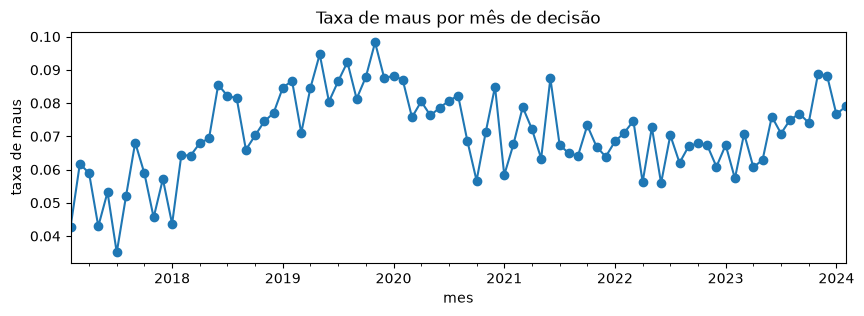

In [68]:
COL_DATA = "data_decisao"
COL_CLIENTE = "id_cliente"
COL_TARGET = "OVER60MOB12"

# Volume e taxa de maus por mês de decisão (somente base_treino)
# ------------------------------------------------------------------
assert base_treino[COL_DATA].notna().all()

mes = base_treino[COL_DATA].dt.to_period("M")
alvo = base_treino[COL_TARGET].astype("float")

por_mes = (
    pd.DataFrame({"mes": mes, "alvo": alvo, "cliente": base_treino[COL_CLIENTE]})
    .groupby("mes")
    .agg(
        n_contratos=("alvo", "size"),
        n_clientes=("cliente", "nunique"),
        n_maus=("alvo", "sum"),
        taxa_maus=("alvo", "mean"),
    )
)
display(por_mes)

# Gráfico simples: taxa de maus e volume por mês
ax = por_mes["taxa_maus"].plot(marker="o", figsize=(10, 3), title="Taxa de maus por mês de decisão")
ax.set_ylabel("taxa de maus")

In [69]:
# Cenários de corte (proporção de treino x embargo)
# ------------------------------------------------------------------
PROPORCOES = [0.80, 0.70]       # fração temporal de contratos para o treino
EMBARGOS_DIAS = [0, 360]        # 360 = horizonte do target (MOB 12)

n_total = len(base_treino)
linhas = []

for prop in PROPORCOES:
    data_corte = base_treino[COL_DATA].quantile(prop)

    for embargo in EMBARGOS_DIAS:
        # Treino: decisões até (corte - embargo). Teste: decisões após o corte.
        limite_treino = data_corte - pd.Timedelta(days=embargo)
        treino = base_treino.loc[base_treino[COL_DATA] <= limite_treino]
        teste = base_treino.loc[base_treino[COL_DATA] > data_corte]

        # Clientes do teste que também aparecem no treino (vetorizado)
        em_comum = teste[COL_CLIENTE].isin(treino[COL_CLIENTE].unique())
        teste_novos = teste.loc[~em_comum]

        linhas.append({
            "prop_treino": prop,
            "embargo_dias": embargo,
            "data_corte": data_corte.date(),
            "n_treino": len(treino),
            "pct_treino": len(treino) / n_total,
            "n_teste_bruto": len(teste),
            "pct_teste_bruto": len(teste) / n_total,
            "pct_teste_com_cliente_no_treino": em_comum.mean(),
            "n_teste_novos": len(teste_novos),
            "pct_teste_novos": len(teste_novos) / n_total,
            "n_maus_teste_novos": int(teste_novos[COL_TARGET].astype("float").sum()),
            "taxa_maus_treino": treino[COL_TARGET].astype("float").mean(),
            "taxa_maus_teste_novos": teste_novos[COL_TARGET].astype("float").mean(),
        })

cenarios = pd.DataFrame(linhas)
display(cenarios)

,prop_treino,embargo_dias,data_corte,n_treino,pct_treino,n_teste_bruto,pct_teste_bruto,pct_teste_com_cliente_no_treino,n_teste_novos,pct_teste_novos,n_maus_teste_novos,taxa_maus_treino,taxa_maus_teste_novos
0,0.8,0,2023-06-06,83335,0.800090,20822,0.19991,0.709874,6041,0.057999,784,0.069695,0.129780
1,0.8,360,2023-06-06,59535,0.571589,20822,0.19991,0.579051,8765,0.084152,983,0.071790,0.112151
2,0.7,0,2023-01-17,72913,0.700030,31244,0.29997,0.683139,9900,0.095049,1166,0.070618,0.117778
3,0.7,360,2023-01-17,52562,0.504642,31244,0.29997,0.563436,13640,0.130956,1417,0.072448,0.103886


### Decisões de Split e Validação

1. **Eixo temporal:** `data_decisao`, a mesma origem da target.
2. **Proporção:** 80/20 por quantil de `data_decisao` (corte em 2023-06-06).
3. **Teste final:** todos os contratos com `data_decisao` posterior ao corte (20.822), idêntico nos dois cenários de treino.
4. **Clientes recorrentes:** nenhum cliente é removido do treino nem do teste. Em produção chegam clientes novos e recorrentes, então o teste completo é o resultado oficial.
5. **Métricas em três recortes** sobre o mesmo modelo: teste completo (oficial), clientes novos (sem contrato no treino) e clientes recorrentes (com contrato no treino). Os recortes diagnosticam o efeito de identidade e não substituem o oficial. As populações têm risco-base diferente (taxa de maus de clientes novos acima da do treino), então os AUCs não são diretamente comparáveis em nível.
6. **Embargo de 360 dias:** o rótulo de um contrato só é conhecido 360 dias após a decisão. Contratos de treino próximos ao corte teriam rótulos desconhecidos na data do corte. O embargo remove do treino decisões posteriores a (corte - 360 dias).
7. **Dois cenários de treino, avaliados antes de eleger o principal:**
   - Com embargo: treino com `data_decisao <= corte - 360 dias` (59.535 contratos).
   - Sem embargo: treino com `data_decisao <= corte` (83.335 contratos).
9. **Validação interna (walk-forward):** folds cronológicos expansivos dentro do treino, com gap entre treino e validação e agrupamento por `id_cliente`. Usada para hiperparâmetros e para acompanhar a evolução da métrica no tempo, sem consultar o teste.

#### Reporte obrigatório
Para cada cenário e recorte: tamanho, número de clientes, taxa de maus, AUC e KS. Na validação interna: AUC e KS por fold, em ordem cronológica.

#### Limitações
- O teste contém apenas safras maduras e não cobre as mais recentes nem a submissão.
- A taxa de maus em clientes novos no teste é maior que no treino; a causa não foi isolada (perfil de risco dos novos ou mudança de nível ao longo do tempo).
- Clientes recorrentes podem ter AUC inflado por memorização de atributos individuais, em parte legítima, pois em produção eles também terão histórico.

## Construção do baseline

In [70]:
base_treino['data_decisao'].dt.to_period("M").nunique()

85

In [71]:
# ------------------------------------------------------------------
# Parâmetros
# ------------------------------------------------------------------
COL_DATA, COL_CLIENTE, COL_TARGET = "data_decisao", "id_cliente", "OVER60MOB12"
PROP_TREINO = 0.80
EMBARGO_DIAS = 360
N_FOLDS = 4
SEED = 42

POS_DECISAO = [
    "status_contrato", "motivo_recusa", "valor_credito_concedido",
    "data_liberacao", "data_primeiro_vencimento",
    "data_ultimo_vencimento_original", "data_ultimo_vencimento", "data_encerramento",
]
IDENTIFICADORES = ["id_contrato", COL_CLIENTE, COL_DATA]
FORA_POR_TIPO = ["data_nascimento"]  # idade será criada na engenharia de features
SUSPEITAS = ["indicador_ultima_solicitacao_contrato", "indicador_ultima_solicitacao_dia"]

EXCLUIR = POS_DECISAO + IDENTIFICADORES + FORA_POR_TIPO + SUSPEITAS + [COL_TARGET]
assert set(EXCLUIR).issubset(base_treino.columns), "Coluna de exclusão inexistente"
FEATURES = [c for c in base_treino.columns if c not in EXCLUIR]
assert set(FEATURES).isdisjoint(EXCLUIR)

# Hiperparâmetros conservadores e fixos (baseline, sem tuning)
PARAMS = dict(
    learning_rate=0.05, max_iter=200, max_depth=4, min_samples_leaf=200,
    l2_regularization=1.0, categorical_features="from_dtype",
    early_stopping=False, random_state=SEED,
)

# ------------------------------------------------------------------
# Funções auxiliares (sem apply/lambda)
# ------------------------------------------------------------------
def preparar_X(df, features):
    """Seleciona features e converte inteiros anuláveis para float64 (NA -> NaN)."""
    X = df[features].copy()
    for col in X.columns:
        if str(X[col].dtype) in ("Int64", "Int8"):
            X[col] = X[col].astype("float64")
    return X

def ks_stat(y, p):
    """KS = maior distância entre as curvas acumuladas de bons e maus."""
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))

def metricas(y, p):
    """AUC e KS; devolve NaN se o recorte tiver uma só classe."""
    if pd.Series(y).nunique() < 2:
        return np.nan, np.nan
    return roc_auc_score(y, p), ks_stat(y, p)

def treinar(df_treino):
    modelo = HistGradientBoostingClassifier(**PARAMS)
    modelo.fit(preparar_X(df_treino, FEATURES), df_treino[COL_TARGET].astype("int8"))
    return modelo

# Limite de categorias do algoritmo (255) respeitado?
cats = [c for c in FEATURES if str(base_treino[c].dtype) == "category"]
assert all(base_treino[c].cat.categories.size <= 255 for c in cats)

# ------------------------------------------------------------------
# 1) Split OOT: teste idêntico; só o treino muda
# ------------------------------------------------------------------
data_corte = base_treino[COL_DATA].quantile(PROP_TREINO)
teste = base_treino.loc[base_treino[COL_DATA] > data_corte]
treinos = {
    "sem_embargo": base_treino.loc[base_treino[COL_DATA] <= data_corte],
    "com_embargo": base_treino.loc[base_treino[COL_DATA] <= data_corte - pd.Timedelta(days=EMBARGO_DIAS)],
}

linhas = []
for nome, tr in treinos.items():
    assert tr[COL_DATA].max() < teste[COL_DATA].min() or nome == "sem_embargo"
    modelo = treinar(tr)
    p = modelo.predict_proba(preparar_X(teste, FEATURES))[:, 1]
    y = teste[COL_TARGET].astype("int8").to_numpy()

    # Recortes: clientes novos x recorrentes (relativos a cada treino)
    recorrente = teste[COL_CLIENTE].isin(tr[COL_CLIENTE].unique()).to_numpy()
    recortes = {"completo": np.ones(len(teste), dtype=bool),
                "novos": ~recorrente, "recorrentes": recorrente}
    for rec, m in recortes.items():
        auc, ks = metricas(y[m], p[m])
        linhas.append({"cenario": nome, "recorte": rec, "n": int(m.sum()),
                       "taxa_maus": y[m].mean(), "auc": auc, "ks": ks})

    # Treino: AUC/KS no próprio treino para medir overfitting
    ptr = modelo.predict_proba(preparar_X(tr, FEATURES))[:, 1]
    auc_tr, ks_tr = metricas(tr[COL_TARGET].astype("int8"), ptr)
    linhas.append({"cenario": nome, "recorte": "treino (in-sample)", "n": len(tr),
                   "taxa_maus": tr[COL_TARGET].astype("float").mean(), "auc": auc_tr, "ks": ks_tr})

resultado_teste = pd.DataFrame(linhas)
print(f"Data de corte: {data_corte.date()} | features: {len(FEATURES)}")
display(resultado_teste)

# ------------------------------------------------------------------
# 2) Walk-forward interno (usa só o treino com embargo; teste não é tocado)
# ------------------------------------------------------------------
MIN_MAUS_TREINO_FOLD = 300   # parâmetro nomeado: ajuste conforme os volumes observados
MIN_MAUS_VAL_FOLD = 100

def features_sem_variacao(X):
    """Colunas com menos de 2 valores distintos não nulos (quebram o binning)."""
    n_distintos = X.nunique(dropna=True)
    return n_distintos.index[n_distintos < 2].tolist()

def treinar_fold(df_treino, features):
    """Treina removendo features constantes/vazias do fold; devolve modelo, features usadas e removidas."""
    X = preparar_X(df_treino, features)
    removidas = features_sem_variacao(X)
    usadas = [c for c in features if c not in removidas]
    modelo = HistGradientBoostingClassifier(**PARAMS)
    modelo.fit(X[usadas], df_treino[COL_TARGET].astype("int8"))
    return modelo, usadas, removidas

tr_base = treinos["com_embargo"]
limites = tr_base[COL_DATA].quantile(np.linspace(0, 1, N_FOLDS + 2)).to_numpy()
folds = []

for k in range(1, N_FOLDS + 1):
    ini_val, fim_val = pd.Timestamp(limites[k]), pd.Timestamp(limites[k + 1])
    val = tr_base.loc[(tr_base[COL_DATA] > ini_val) & (tr_base[COL_DATA] <= fim_val)]

    # Treino do fold: passado com gap, sem clientes presentes na validação
    tr_fold = tr_base.loc[tr_base[COL_DATA] <= ini_val - pd.Timedelta(days=EMBARGO_DIAS)]
    tr_fold = tr_fold.loc[~tr_fold[COL_CLIENTE].isin(val[COL_CLIENTE].unique())]
    assert set(tr_fold[COL_CLIENTE]).isdisjoint(set(val[COL_CLIENTE]))

    n_maus_tr = int(tr_fold[COL_TARGET].astype("float").sum())
    n_maus_val = int(val[COL_TARGET].astype("float").sum())
    registro = {"fold": k, "val_inicio": ini_val.date(), "val_fim": fim_val.date(),
                "n_treino": len(tr_fold), "maus_treino": n_maus_tr,
                "n_val": len(val), "maus_val": n_maus_val,
                "auc": np.nan, "ks": np.nan, "features_removidas": "", "status": "ok"}

    if n_maus_tr < MIN_MAUS_TREINO_FOLD or n_maus_val < MIN_MAUS_VAL_FOLD:
        registro["status"] = "ignorado: maus insuficientes"
        folds.append(registro)
        continue

    modelo, usadas, removidas = treinar_fold(tr_fold, FEATURES)
    pv = modelo.predict_proba(preparar_X(val, usadas))[:, 1]
    registro["auc"], registro["ks"] = metricas(val[COL_TARGET].astype("int8"), pv)
    registro["features_removidas"] = ", ".join(removidas)
    folds.append(registro)

resultado_folds = pd.DataFrame(folds)
display(resultado_folds)

Data de corte: 2023-06-06 | features: 36


,cenario,recorte,n,taxa_maus,auc,ks
0,sem_embargo,completo,20822,0.078667,0.623740,0.210562
1,sem_embargo,novos,6041,0.129780,0.529942,0.063257
2,sem_embargo,recorrentes,14781,0.057777,0.580154,0.148317
3,sem_embargo,treino (in-sample),83335,0.069695,0.728560,0.341448
4,com_embargo,completo,20822,0.078667,0.583671,0.133716
5,com_embargo,novos,8765,0.112151,0.552959,0.083574
6,com_embargo,recorrentes,12057,0.054325,0.585336,0.141575
7,com_embargo,treino (in-sample),59535,0.071790,0.737925,0.357173


,fold,val_inicio,val_fim,n_treino,maus_treino,n_val,maus_val,auc,ks,features_removidas,status
0,1,2018-07-02,2019-08-29,1842,116,11894,957,NaN,NaN,,ignorado: maus insuficientes
1,2,2019-08-29,2020-10-17,9740,684,11911,965,0.575763,0.124076,"taxa_juros_padrao, taxa_juros_promocional",ok
2,3,2020-10-17,2021-09-19,18058,1454,11903,841,0.609114,0.169454,,ok
3,4,2021-09-19,2022-06-11,25574,2186,11904,808,0.589099,0.144652,,ok


In [74]:
import importlib
import src.functions as fn
importlib.reload(fn)

COL_DATA, COL_CLIENTE, COL_TARGET = "data_decisao", "id_cliente", "OVER60MOB12"
PROP_TREINO, EMBARGO_DIAS, N_FOLDS = 0.80, 360, 4
MIN_MAUS_TREINO_FOLD, MIN_MAUS_VAL_FOLD = 300, 100

EXCLUIR = (
    ["status_contrato", "motivo_recusa", "valor_credito_concedido", "data_liberacao",
     "data_primeiro_vencimento", "data_ultimo_vencimento_original",
     "data_ultimo_vencimento", "data_encerramento"]
    + ["id_contrato", COL_CLIENTE, COL_DATA, "data_nascimento"]
    + ["indicador_ultima_solicitacao_contrato", "indicador_ultima_solicitacao_dia"]
    + [COL_TARGET]
)
FEATURES = fn.selecionar_features(base_treino, EXCLUIR)

# Split: teste idêntico, só o treino muda
tr_sem, teste, data_corte = fn.dividir_oot(base_treino, COL_DATA, PROP_TREINO, 0)
tr_com, _, _ = fn.dividir_oot(base_treino, COL_DATA, PROP_TREINO, EMBARGO_DIAS)

resultado_teste = fn.avaliar_oot({"sem_embargo": tr_sem, "com_embargo": tr_com},
                                 teste, FEATURES, COL_TARGET, COL_CLIENTE)
resultado_folds = fn.walk_forward(tr_com, FEATURES, COL_DATA, COL_CLIENTE, COL_TARGET,
                                  N_FOLDS, EMBARGO_DIAS, MIN_MAUS_TREINO_FOLD, MIN_MAUS_VAL_FOLD)
display(resultado_teste, resultado_folds)

,cenario,recorte,n,taxa_maus,auc,ks
0,sem_embargo,completo,20822,0.078667,0.623740,0.210562
1,sem_embargo,novos,6041,0.129780,0.529942,0.063257
2,sem_embargo,recorrentes,14781,0.057777,0.580154,0.148317
3,sem_embargo,treino (in-sample),83335,0.069695,0.728560,0.341448
4,com_embargo,completo,20822,0.078667,0.583671,0.133716
5,com_embargo,novos,8765,0.112151,0.552959,0.083574
6,com_embargo,recorrentes,12057,0.054325,0.585336,0.141575
7,com_embargo,treino (in-sample),59535,0.071790,0.737925,0.357173


,fold,val_inicio,val_fim,n_treino,maus_treino,n_val,maus_val,auc,ks,features_removidas,status
0,1,2018-07-02,2019-08-29,1842,116,11894,957,NaN,NaN,,ignorado: maus insuficientes
1,2,2019-08-29,2020-10-17,9740,684,11911,965,0.575763,0.124076,"taxa_juros_padrao, taxa_juros_promocional",ok
2,3,2020-10-17,2021-09-19,18058,1454,11903,841,0.609114,0.169454,,ok
3,4,2021-09-19,2022-06-11,25574,2186,11904,808,0.589099,0.144652,,ok


In [73]:
# Proporção de nulos das taxas de juros por ano de decisão (hipótese: preenchimento depende da época)
cols_taxa = ["taxa_juros_padrao", "taxa_juros_promocional"]
nulos_ano = (
    base_treino[cols_taxa].isna()
    .groupby(base_treino[COL_DATA].dt.year)
    .mean()
)
display(nulos_ano)

,taxa_juros_padrao,taxa_juros_promocional
data_decisao,,
2017,1.000000,1.000000
2018,0.999622,0.999622
2019,0.999696,0.999696
2020,0.999190,0.999190
2021,0.999400,0.999400
2022,0.999703,0.999703
2023,0.992421,0.992421
2024,0.987323,0.987323
